# Ручное обогащение реальными данными: анализ до и после

**Этап 18.11.26:** ручное обогащение реальными данными, разметка двумя аннотаторами, codebook.

| | Исходный датасет | Ручное обогащение |
|---|---|---|
| Тексты | RuSentiTweet, 13 392 твита | 70 реальных сообщений пользователей русскоязычных платформ (корпус Skoltech, CC BY-NC-SA 4.0) |
| Фото | TrashNet, 2 527 фото на белом фоне | 63 реальных фото отходов в разных условиях (TrashBox) |

Отбор воспроизводим: `python -m src.collect_real` (фиксированный `random_state`). Разметка — двумя разметчиками по codebook (`docs/codebook_*.md`), сборка и согласие — `python -m src.annotation_merge`.

Части 1–2 сравнивают **сами данные** (не зависят от меток). Часть 3 — метки, она заполняется после разметки.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from PIL import Image
from src import eda_text as T, eda_images as I

OUT = ROOT / "reports" / "eda_after"; OUT.mkdir(parents=True, exist_ok=True)
REAL = ROOT / "data" / "enriched" / "real"
sns.set_theme(style="whitegrid"); plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_colwidth", 140)
save = lambda fig, n: fig.savefig(OUT / f"{n}.png", bbox_inches="tight")

## 1. Тексты: чем новые сообщения отличаются от RuSentiTweet

In [2]:
orig = pd.read_csv(ROOT / "data/raw/rusentitweet/rusentitweet_full.csv", index_col=0)
new = pd.read_csv(REAL / "texts.csv")
print("RuSentiTweet:", len(orig), "| новые:", len(new))
print("Способ отбора:", new["sampling"].value_counts().to_dict())
new[["id", "text", "sampling"]].head(10)

RuSentiTweet: 13392 | новые: 70
Способ отбора: {'random': 40, 'targeted': 30}


,id,text,sampling
0,t001,"А я все равно верю что меня где-то ждет другая жизнь, новая, без тягостного прошлого и самое обидное что я ничего не делаю чтобы в ту жи...",random
1,t002,Часто слышу от тянПочему тебя волнует их мнение?,random
2,t003,"Прошел игру с полностью вкаченным одноручем 5 класса, кому ты заливаешь?",targeted
3,t004,"Так просто скажут, чтобы побыстрей выполнит работу, или мне действительно не о чем беспокоиться?",random
4,t005,думаю время покажет... любовь это или что... а так хочу пожелать терпения и удачи,targeted
5,t006,Для литературного языка так говорить нельзя. Для научно-технического - можно.,random
6,t007,"Жакет его зовут, а его главная фраза в пуйдуе -",random
7,t008,это самый сложный выбор в жизни каждого человека,random
8,t009,Спасибо что напомнил с цветом разобраться. Через рандомайзер прогнал.,targeted
9,t010,Не рискуйте ускориться на тот свет,random


In [3]:
Fo = T.add_features(orig.assign(label="?")).assign(set="RuSentiTweet")
Fn = T.add_features(new.assign(label="?")).assign(set="Обогащение (реальные)")
cols = ["n_chars", "n_words", "has_url", "has_mention", "has_hashtag", "n_emoji", "cyr_share"]
comp = pd.DataFrame({
    "RuSentiTweet": [Fo.n_chars.median(), Fo.n_words.median(), Fo.has_url.mean(), Fo.has_mention.mean(),
                     Fo.has_hashtag.mean(), (Fo.n_emoji > 0).mean(), Fo.cyr_share.mean()],
    "Обогащение": [Fn.n_chars.median(), Fn.n_words.median(), Fn.has_url.mean(), Fn.has_mention.mean(),
                   Fn.has_hashtag.mean(), (Fn.n_emoji > 0).mean(), Fn.cyr_share.mean()],
}, index=["медиана символов", "медиана слов", "доля со ссылкой", "доля с @упоминанием",
          "доля с хештегом", "доля с эмодзи", "средняя доля кириллицы"]).round(3)
comp

,RuSentiTweet,Обогащение
медиана символов,52.000,73.500
медиана слов,6.000,11.000
доля со ссылкой,0.210,0.000
доля с @упоминанием,0.596,0.000
доля с хештегом,0.022,0.000
доля с эмодзи,0.177,0.000
средняя доля кириллицы,0.993,0.998


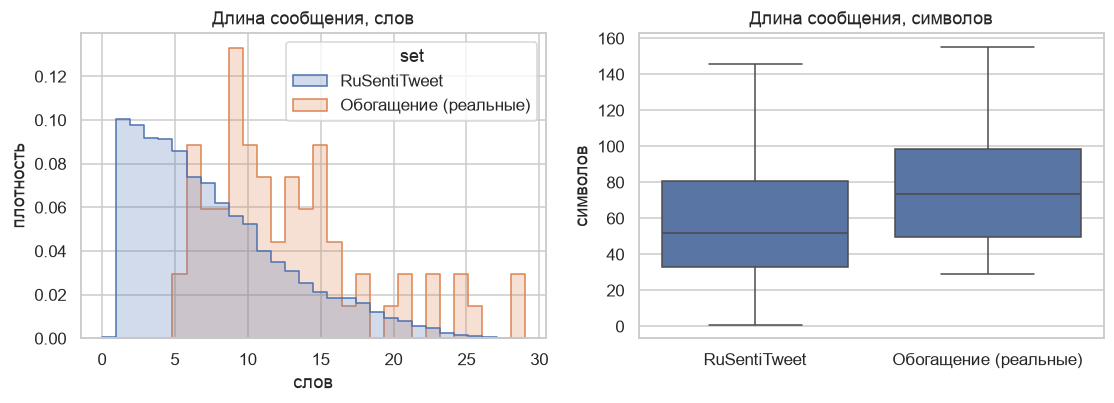

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
both = pd.concat([Fo, Fn])
sns.histplot(data=both, x="n_words", hue="set", stat="density", common_norm=False, bins=30, ax=axes[0], element="step")
axes[0].set(title="Длина сообщения, слов", xlabel="слов", ylabel="плотность")
sns.boxplot(data=both, x="set", y="n_chars", ax=axes[1], showfliers=False)
axes[1].set(title="Длина сообщения, символов", xlabel="", ylabel="символов")
save(fig, "text_length_compare")

In [5]:
vocab = {w for s in orig["text"] for w in T.RE_WORD.findall(T.clean_for_tokens(s))}
toks = [w for s in new["text"] for w in T.RE_WORD.findall(T.clean_for_tokens(s))]
oov = np.mean([w not in vocab for w in toks])
print(f"Доля словоупотреблений новых текстов, которых нет в словаре RuSentiTweet (OOV): {oov:.1%}")
print("Частотные слова в новых текстах:", [w for w, _ in T.top_tokens(new.assign(label='?'), None, 15)])

Доля словоупотреблений новых текстов, которых нет в словаре RuSentiTweet (OOV): 20.6%
Частотные слова в новых текстах: ['спасибо', 'балла', 'класса', 'люблю', 'рада', 'жаль', 'равно', 'ждет', 'жизнь', 'часто', 'удачи', 'литературного', 'жизни', 'хотя', 'ура']


**Вывод.** Новые сообщения почти вдвое длиннее твитов (медиана 11 слов против 6): это форумные ответы и вопросы, а не реплики в ленте. Упоминаний, ссылок, хештегов и эмодзи в них нет (в RuSentiTweet упоминания есть в 60 % твитов, эмодзи — в 18 %). Около 20 % словоупотреблений отсутствуют в словаре RuSentiTweet: это другой «жанр» с той же разговорной лексикой. Поэтому обогащение проверяет не только баланс классов, но и **переносимость модели на соседний домен**. Долю OOV стоит сравнить с ростом ошибок модели на этих данных.

## 2. Фото: новые условия съёмки против TrashNet

In [6]:
tn = I.scan(ROOT / "data/raw/trashnet/dataset-resized", phash=True).assign(set="TrashNet")
man = pd.read_csv(REAL / "images_manifest.csv").sort_values("order")
nw = I.scan_files([(REAL / f, None) for f in man["file"]], phash=True).assign(set="Обогащение (реальные)")
print("TrashNet:", len(tn), "| новые:", len(nw))
print("Разрешения новых фото:", nw[["width", "height"]].value_counts().head(5).to_dict())
stats = pd.concat([tn, nw]).groupby("set")[["brightness", "contrast", "colorfulness", "aspect"]].agg(["median", "std"]).round(3)
stats

TrashNet: 2527 | новые: 63
Разрешения новых фото: {(512, 512): 9, (512, 341): 6, (300, 300): 5, (250, 250): 3, (512, 288): 2}


brightness        contrast        colorfulness         \
                          median    std   median    std       median    std   
set                                                                           
TrashNet                   0.657  0.081    0.191  0.062        0.092  0.068   
Обогащение (реальные)      0.606  0.238    0.235  0.074        0.104  0.106   

                      aspect         
                      median    std  
set                                  
TrashNet               1.333  0.000  
Обогащение (реальные)  1.000  0.345

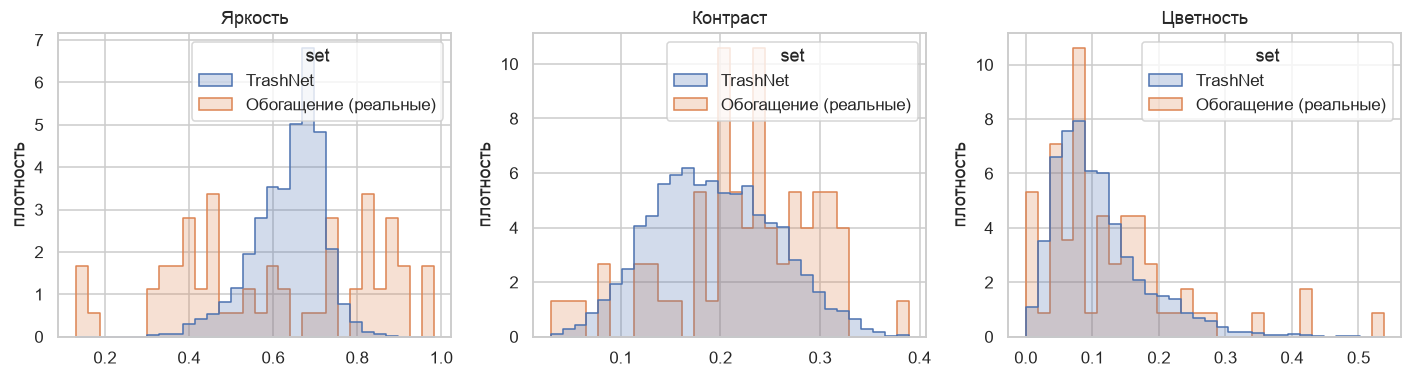

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
both = pd.concat([tn, nw])
for ax, col, t in zip(axes, ["brightness", "contrast", "colorfulness"], ["Яркость", "Контраст", "Цветность"]):
    sns.histplot(data=both, x=col, hue="set", stat="density", common_norm=False, bins=30, element="step", ax=ax)
    ax.set(title=t, xlabel="", ylabel="плотность")
plt.tight_layout(); save(fig, "img_stats_compare")

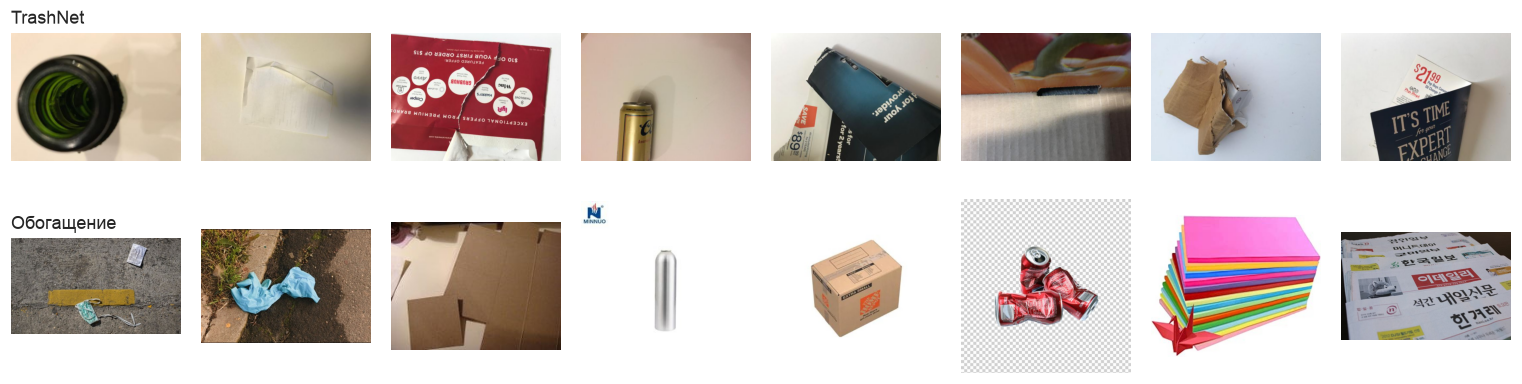

In [8]:
fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for ax, p in zip(axes[0], tn.sample(8, random_state=0)["path"]):
    ax.imshow(Image.open(p)); ax.axis("off")
for ax, p in zip(axes[1], nw.head(8)["path"]):
    ax.imshow(Image.open(p)); ax.axis("off")
axes[0, 0].set_title("TrashNet", loc="left"); axes[1, 0].set_title("Обогащение", loc="left")
plt.tight_layout(); save(fig, "img_examples_compare")

In [9]:
# пересечения с TrashNet по pHash (новые фото не должны быть копиями старых)
import imagehash
th = [imagehash.hex_to_hash(h) for h in tn["phash"]]
dmin = [min(imagehash.hex_to_hash(h) - x for x in th) for h in nw["phash"]]
print("Минимальное расстояние pHash до TrashNet: медиана", int(np.median(dmin)), "| ≤4 (копии):", int(np.sum(np.array(dmin) <= 4)))
rej = pd.read_csv(REAL / "images_rejected_trashnet_copies.csv")
print("Отброшено при отборе как копии TrashNet:", len(rej))
print("Состав по подклассам источника (служебно, разметчикам не показывается):")
man["source_subclass"].value_counts()

Минимальное расстояние pHash до TrashNet: медиана 16 | ≤4 (копии): 0
Отброшено при отборе как копии TrashNet: 6
Состав по подклассам источника (служебно, разметчикам не показывается):


source_subclass
cardboard             10
glass                 10
beverage cans          4
paper                  4
tetra pak              4
masks                  3
gloves                 3
spray cans             3
news paper             3
metal containers       3
plastic containers     3
paper cups             3
plastic bottles        3
plastic bags           3
cigarette butt         2
plastic cups           2
Name: count, dtype: int64

**Вывод.** Условия съёмки новых фото гораздо разнообразнее, чем в TrashNet: у TrashNet одно разрешение и пропорция 4:3, у новых — разные размеры и пропорции; стандартное отклонение яркости почти в 3 раза больше (0,24 против 0,08), цветности — в 1,6 раза, контраста — в 1,2 раза. Медиана яркости близка к TrashNet (0,61 против 0,66), потому что много стоковых снимков на светлом фоне. Значит, сдвиг домена здесь — это прежде всего **разнообразие** фона, освещения, ракурса и кадрирования. Это то, к чему должна стать устойчивее модель после обогащения.

**Утечка данных.** TrashBox собран из интернета и содержит фото из самого TrashNet. При отборе такие фото отбрасывались по pHash (расстояние ≤ 4): найдено и исключено 6 копий (`data/enriched/real/images_rejected_trashnet_copies.csv`). Без этой проверки одно и то же фото попало бы и в исходный датасет, и в «новые данные» и завысило бы оценку модели.

Часть новых фото — стоковые снимки с водяными знаками и нерелевантные картинки: для них в codebook есть метка `exclude`, их доля — показатель «грязности» веб-источника.

## 3. Разметка: согласие и распределение классов до и после

**Разметчики.** Разметку по codebook v1.1 выполнили исполнители, каждый отдельно, без доступа к меткам другого и к классам источника:
- **A** — Шалыгин Ярослав;
- **B** — Соколов Александр.

Как черновик использовалась предварительная автоматическая разметка (см. `docs/llm_protocol.md`). Каждый из нас просмотрел все объекты и исправил метки по codebook.

Расхождения (10 текстов, 4 фото) мы разобрали вместе по codebook и записали обоснование для каждого решения (`data/annotation/arbitration.csv`).

**Ограничение согласия.** Оба разметчика начинали с одного и того же черновика, поэтому $\kappa$, скорее всего, выше, чем при полностью независимой разметке с нуля. Сравнивать её с $\alpha \approx 0{,}505$ краудсорсинговой разметки RuSentiTweet напрямую нельзя.

In [10]:
ann_path = ROOT / "data/annotation/annotations_all.csv"
if not ann_path.exists():
    print("Разметка ещё не собрана: заполните листы data/annotation/sheets/*.xlsx и запустите python -m src.annotation_merge")
else:
    ann = pd.read_csv(ann_path, dtype=str, keep_default_na=False)
    for ds in ["rusentitweet", "trashnet"]:
        p = ROOT / f"reports/annotation/agreement_{ds}.json"
        if p.exists():
            r = json.loads(p.read_text())
            for pr in r["pairs"]:
                print(f"{ds}: {pr['a']} × {pr['b']}  N={pr['n']}  P_o={pr['p_o']:.3f}  κ={pr['kappa']:.3f} ({pr['band']})")

rusentitweet: A_shalygin × B_sokolov  N=70  P_o=0.857  κ=0.775 (существенное)
trashnet: A_shalygin × B_sokolov  N=63  P_o=0.936  κ=0.924 (почти полное)


In [11]:
if ann_path.exists():
    fin = ann[ann["final"] != ""]
    rows = []
    to = orig["label"].value_counts()
    tnew = fin[fin.dataset == "rusentitweet"]["final"].value_counts()
    for lab in T.LABEL_ORDER:
        a, b = int(to.get(lab, 0)), int(tnew.get(lab, 0))
        rows.append({"датасет": "тексты", "класс": lab, "до": a, "добавлено": b, "после": a + b,
                     "доля до": a / to.sum(), "доля после": (a + b) / (to.sum() + tnew.sum())})
    io_ = tn["label"].value_counts()
    inew = fin[(fin.dataset == "trashnet") & (fin["final"] != "exclude")]["final"].value_counts()
    for lab in sorted(io_.index):
        a, b = int(io_.get(lab, 0)), int(inew.get(lab, 0))
        rows.append({"датасет": "фото", "класс": lab, "до": a, "добавлено": b, "после": a + b,
                     "доля до": a / io_.sum(), "доля после": (a + b) / (io_.sum() + inew.sum())})
    bal = pd.DataFrame(rows)
    display(bal.style.format({"доля до": "{:.1%}", "доля после": "{:.1%}"}))
    for ds in ["тексты", "фото"]:
        s = bal[bal["датасет"] == ds]
        print(ds, "дисбаланс max/min: до", round(s["до"].max() / s["до"].min(), 2), "→ после", round(s["после"].max() / s["после"].min(), 2))
    print("Исключено фото (exclude):", int((fin["final"] == "exclude").sum()))
    bal.to_csv(OUT / "class_balance_before_after.csv", index=False)

,датасет,класс,до,добавлено,после,доля до,доля после
0,тексты,positive,2414,8,2422,18.0%,18.0%
1,тексты,neutral,5341,43,5384,39.9%,40.0%
2,тексты,negative,3298,7,3305,24.6%,24.6%
3,тексты,speech,496,6,502,3.7%,3.7%
4,тексты,skip,1843,6,1849,13.8%,13.7%
5,фото,cardboard,403,6,409,15.9%,15.9%
6,фото,glass,501,7,508,19.8%,19.7%
7,фото,metal,410,8,418,16.2%,16.2%
8,фото,paper,594,5,599,23.5%,23.2%
9,фото,plastic,482,11,493,19.1%,19.1%


тексты дисбаланс max/min: до 10.77 → после 10.73
фото дисбаланс max/min: до 4.34 → после 3.99
Исключено фото (exclude): 13


**Как читать часть 3.** Согласие $\kappa$ сравнивается с исходными датасетами (RuSentiTweet: Krippendorff $\alpha \approx 0{,}505$). Таблица баланса показывает, насколько ручное обогащение сдвинуло доли редких классов (`speech` в текстах, `trash` в фото). При 70 и 63 новых объектах сдвиг по долям мал. Главная роль этих данных — **тестовый набор из другого домена** и материал для сравнения с искусственным обогащением на следующем этапе.